In [3]:
import pandas as pd
dataset=pd.read_csv("v1Capstone-FP&A_Time_Series_Capstone_Dataset.csv")

In [6]:
dataset.head(130)

,Client Name,Month,Scenario,Revenue GL Account,Revenue,Cost GL Account,Cost,CCI,CCI %
0,Client A,2025-01-01,Actual,400000 - Revenue,965265.51,500000 - Cost,667654.97,297610.54,30.83
1,Client A,2025-02-01,Actual,400000 - Revenue,994900.11,500000 - Cost,703916.22,290983.89,29.25
2,Client A,2025-03-01,Actual,400000 - Revenue,988177.46,500000 - Cost,681429.95,306747.51,31.04
3,Client A,2025-04-01,Actual,400000 - Revenue,1049206.88,500000 - Cost,731790.39,317416.49,30.25
4,Client A,2025-05-01,Actual,400000 - Revenue,1069524.81,500000 - Cost,741368.55,328156.26,30.68
...,...,...,...,...,...,...,...,...,...
115,Client E,2026-08-01,Budget,400000 - Revenue,510111.92,500000 - Cost,366524.48,143587.44,28.15
116,Client E,2026-09-01,Budget,400000 - Revenue,505305.10,500000 - Cost,365202.83,140102.27,27.73
117,Client E,2026-10-01,Budget,400000 - Revenue,525368.68,500000 - Cost,377466.88,147901.80,28.15
118,Client E,2026-11-01,Budget,400000 - Revenue,540729.46,500000 - Cost,388051.30,152678.16,28.24


Text(0, 0.5, 'Revenue')

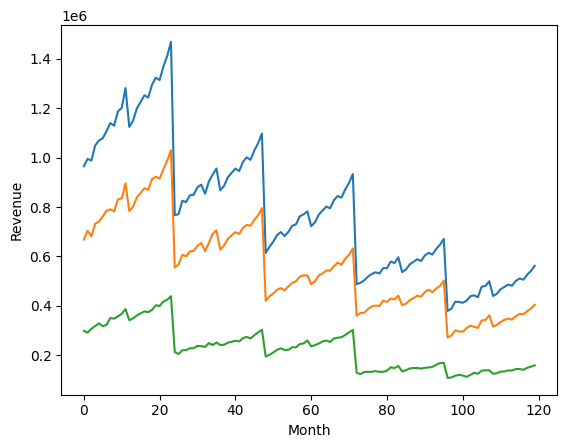

In [37]:
import matplotlib.pyplot as plt
plt.plot(dataset["Revenue"])
plt.plot(dataset["Cost"])
plt.plot(dataset["CCI"])
plt.xlabel("Month")
plt.ylabel("Revenue")

<Figure size 1600x800 with 0 Axes>

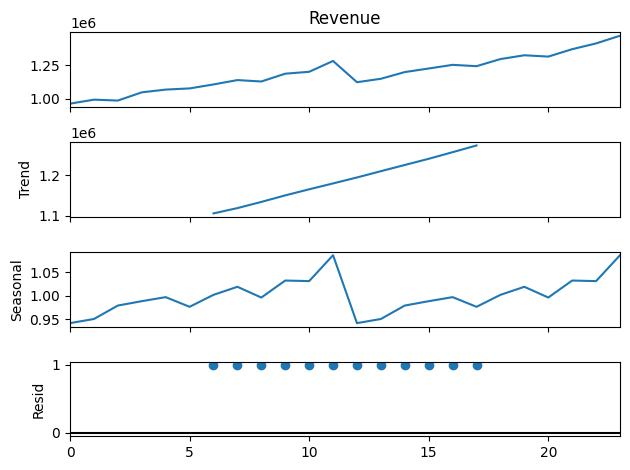

In [45]:
from pandas import read_csv
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
client_data=dataset[dataset['Client Name']=='Client A']
result=seasonal_decompose(client_data["Revenue"],model="multiplicative",period=12)
plt.figure(figsize=(16,8))
result.plot()
plt.tight_layout()
plt.show()

<Figure size 1600x500 with 0 Axes>

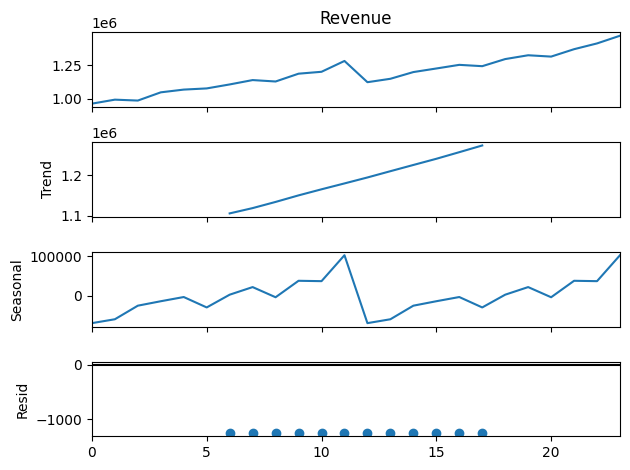

In [49]:
from pandas import read_csv
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(client_data["Revenue"], model='additive',period=12)
plt.figure(figsize=(16,5))
result.plot()
plt.show()

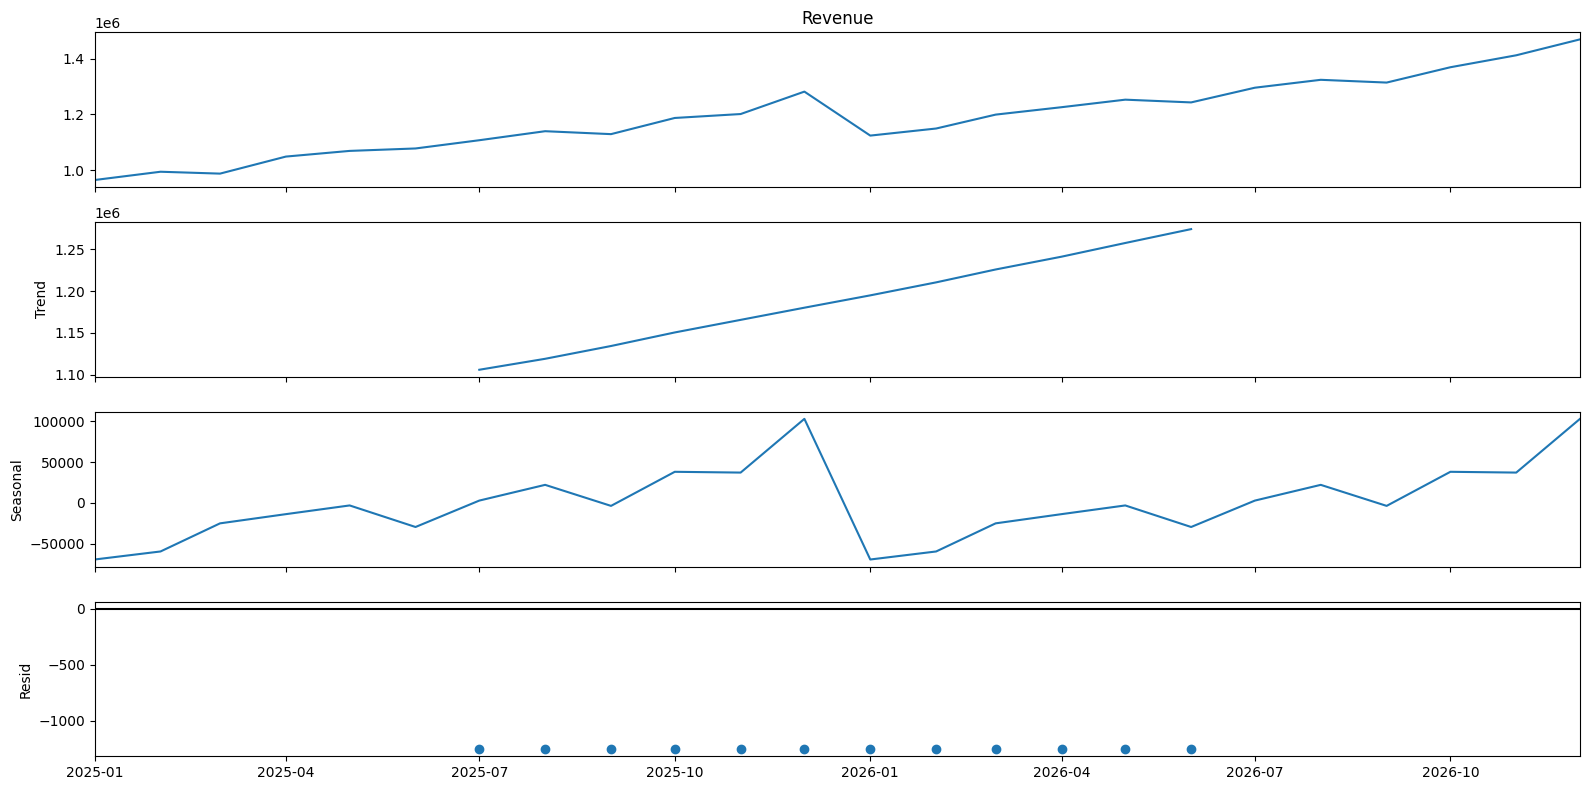

In [50]:
import pandas as pd
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Filter Client A
client_data = dataset[dataset['Client Name'] == 'Client A'].copy()

# Convert Month to datetime
client_data['Month'] = pd.to_datetime(client_data['Month'])

# Sort by Month
client_data = client_data.sort_values('Month')

# Set Month as index
client_data = client_data.set_index('Month')

# Seasonal decomposition
result = seasonal_decompose(
    client_data['Revenue'],
    model='additive',
    period=12
)

# Plot
fig = result.plot()
fig.set_size_inches(16, 8)

plt.tight_layout()
plt.show()

In [51]:
client_data.head()

,Client Name,Scenario,Revenue GL Account,Revenue,Cost GL Account,Cost,CCI,CCI %
Month,,,,,,,,
2025-01-01,Client A,Actual,400000 - Revenue,965265.51,500000 - Cost,667654.97,297610.54,30.83
2025-02-01,Client A,Actual,400000 - Revenue,994900.11,500000 - Cost,703916.22,290983.89,29.25
2025-03-01,Client A,Actual,400000 - Revenue,988177.46,500000 - Cost,681429.95,306747.51,31.04
2025-04-01,Client A,Actual,400000 - Revenue,1049206.88,500000 - Cost,731790.39,317416.49,30.25
2025-05-01,Client A,Actual,400000 - Revenue,1069524.81,500000 - Cost,741368.55,328156.26,30.68


In [52]:

# ADF Test
# Function to print out results in customised manner
from statsmodels.tsa.stattools import adfuller
def adf_test(timeseries,df,pollutant):
    plt.figure(figsize=(16,5))
    # Plot the data
    # ADF Test
    # Function to print out results in customised manner
    from statsmodels.tsa.stattools import adfuller
    print ('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print (dfoutput)
    ans=dfoutput
    print("Condition:")
    print("p-value<=0.05-->Accept Alternate Hypothesis")
    print("p-value>0.05-->Accept Null Hypothesis")
    if(ans['Test Statistic']<ans["Critical Value (1%)"] or ans['Test Statistic']<ans["Critical Value (5%)"] or ans['Test Statistic']<ans["Critical Value (10%)"] and ans["p-value"]<0.05):
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Reject null hypothesis:Non Stationarity")
        print("Accept Alternate hypothesis:Staionarity ")
        message="Stationarity based on ADH"
    else:
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Accept null hypothesis:Non Stationarity" )
        print("Reject Alternate hypothesis:Staionarity ")
        message="Non-stationarity based on ADH"
        
    plt.plot(df.index, df[pollutant], label = pollutant)
    plt.legend(loc='best')
    plt.title("{}_{}_2013 to 2021".format(message,pollutant))
    plt.savefig("{}_ADH.png".format(pollutant))
    plt.show()
    
    return message
    
# Call the function and run the test



Results of Dickey-Fuller Test:
Test Statistic                 -0.354903
p-value                         0.917361
#Lags Used                      0.000000
Number of Observations Used    23.000000
Critical Value (1%)            -3.752928
Critical Value (5%)            -2.998500
Critical Value (10%)           -2.638967
dtype: float64
Condition:
p-value<=0.05-->Accept Alternate Hypothesis
p-value>0.05-->Accept Null Hypothesis
Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis
Accept null hypothesis:Non Stationarity
Reject Alternate hypothesis:Staionarity 


C:\Users\ADMN\AppData\Local\Temp\ipykernel_12196\1000524683.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag='AIC')


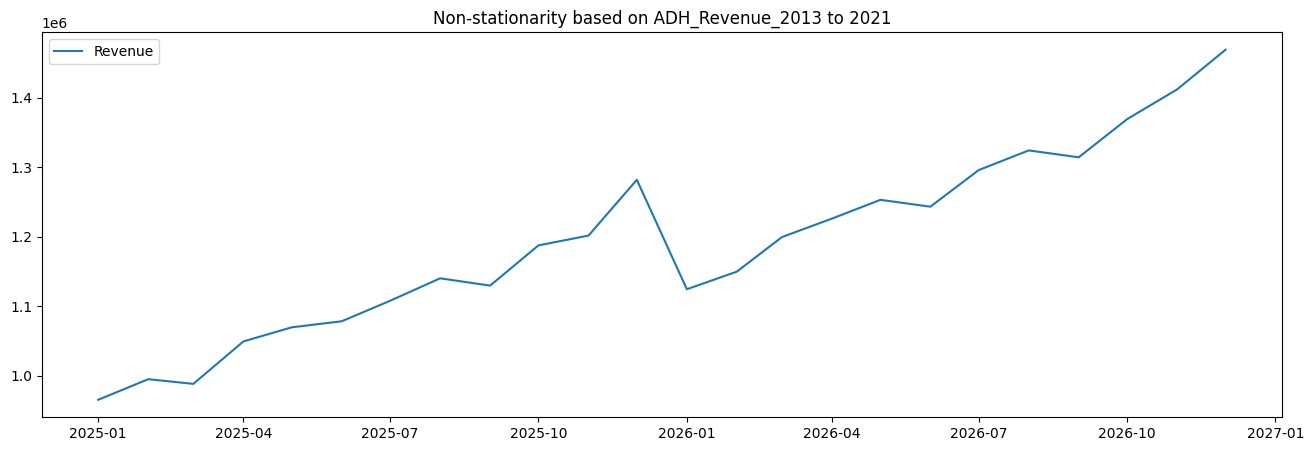

'Non-stationarity based on ADH'

In [53]:
adf_test(client_data["Revenue"],client_data,"Revenue")

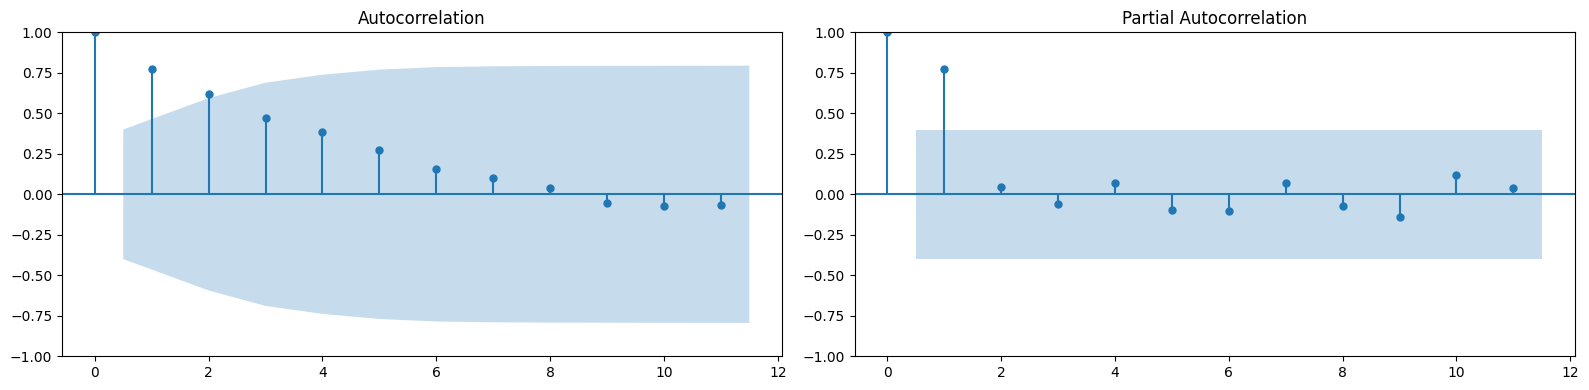

In [58]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(16, 4), dpi=100)

plot_acf(client_data['Revenue'], lags=11, ax=axes[0])

plot_pacf(client_data['Revenue'], lags=11, ax=axes[1], method='ywm')

plt.tight_layout()
plt.show()

In [59]:
# First-order differencing
client_data['Revenue_diff'] = client_data['Revenue'].diff()

# ADF test again
from statsmodels.tsa.stattools import adfuller

result = adfuller(client_data['Revenue_diff'].dropna())

print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -6.2195963421485905
p-value: 5.2627927965020044e-08


C:\Users\ADMN\AppData\Local\Temp\ipykernel_12196\2166056566.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(client_data['Revenue_diff'].dropna())


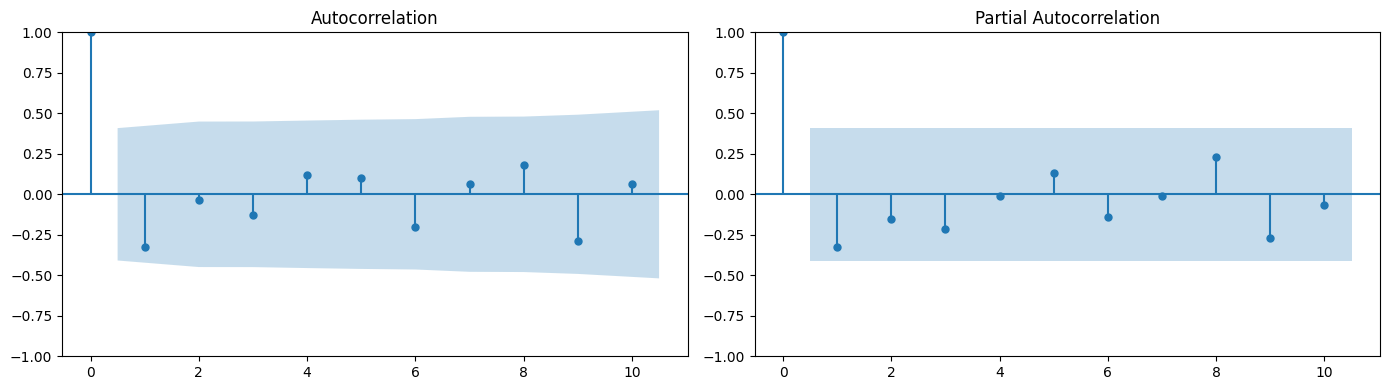

In [60]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(client_data['Revenue_diff'].dropna(),
         lags=10, ax=axes[0])

plot_pacf(client_data['Revenue_diff'].dropna(),
          lags=10, ax=axes[1], method='ywm')

plt.tight_layout()
plt.show()